# High Level Design of ML Systems

## What is HLD and Why It Matters

**High Level Design (HLD)** is the practice of mapping out a system's components and their relationships *before* writing a single line of code. It answers three questions:

1. **What components exist?** — Feature store, model server, monitoring service, data pipeline…
2. **How do they communicate?** — REST APIs, message queues, shared databases, gRPC calls…
3. **What are the tradeoffs?** — Latency vs throughput, consistency vs availability, cost vs performance

In production ML, a model is 5% of the system. The other 95% is infrastructure. HLD is how engineers align on that 95% before committing to code.

> **Key insight:** In notebooks you run cells. In production you design systems. HLD is the language engineers use to talk about production.

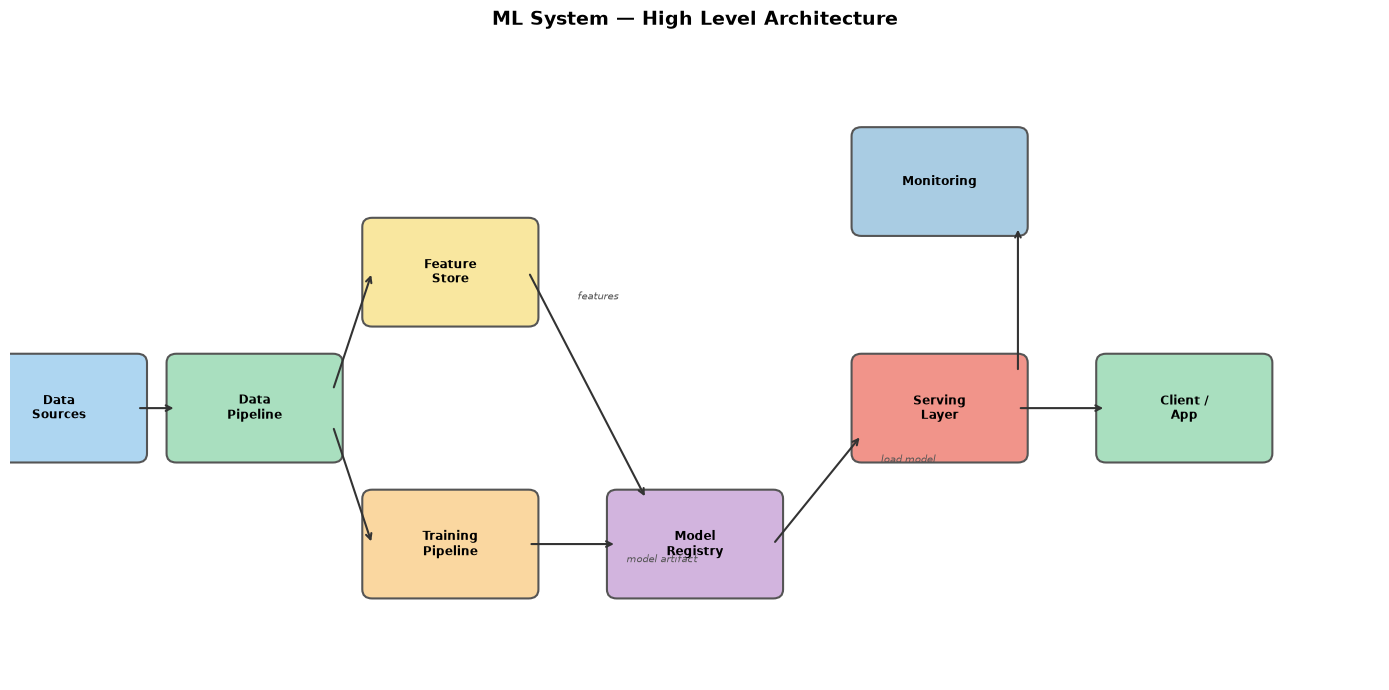

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 14); ax.set_ylim(0, 7); ax.axis('off')
ax.set_title('ML System — High Level Architecture', fontsize=14, fontweight='bold', pad=15)

components = [
    (0.5, 3.0, 'Data\nSources',    '#AED6F1'),
    (2.5, 3.0, 'Data\nPipeline',   '#A9DFBF'),
    (4.5, 4.5, 'Feature\nStore',   '#F9E79F'),
    (4.5, 1.5, 'Training\nPipeline','#FAD7A0'),
    (7.0, 1.5, 'Model\nRegistry',  '#D2B4DE'),
    (9.5, 3.0, 'Serving\nLayer',   '#F1948A'),
    (9.5, 5.5, 'Monitoring',       '#A9CCE3'),
    (12.0,3.0, 'Client /\nApp',    '#A9DFBF'),
]

boxes = {}
for x, y, label, color in components:
    box = mpatches.FancyBboxPatch((x-0.8, y-0.5), 1.6, 1.0,
        boxstyle='round,pad=0.1', facecolor=color, edgecolor='#555', linewidth=1.5)
    ax.add_patch(box)
    ax.text(x, y, label, ha='center', va='center', fontsize=8.5, fontweight='bold')
    boxes[label.replace('\n',' ')] = (x, y)

arrows = [
    ((1.3,3.0),(1.7,3.0)),
    ((3.3,3.2),(3.7,4.5)),
    ((3.3,2.8),(3.7,1.5)),
    ((5.3,4.5),(6.5,2.0)),
    ((5.3,1.5),(6.2,1.5)),
    ((7.8,1.5),(8.7,2.7)),
    ((10.3,3.0),(11.2,3.0)),
    ((10.3,3.4),(10.3,5.0)),
]
for (x1,y1),(x2,y2) in arrows:
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
        arrowprops=dict(arrowstyle='->', color='#333', lw=1.5))

ax.text(5.8, 4.2, 'features', fontsize=7, color='#555', style='italic')
ax.text(6.3, 1.3, 'model artifact', fontsize=7, color='#555', style='italic')
ax.text(8.9, 2.4, 'load model', fontsize=7, color='#555', style='italic')
plt.tight_layout(); plt.show()

## Architecture Patterns

### Batch vs Real-Time Inference

| Dimension | Batch | Real-Time |
|-----------|-------|----------|
| **Latency** | Hours / minutes | < 100ms |
| **Throughput** | Millions of rows | Hundreds of RPS |
| **Use case** | Churn scoring, recommendations pre-computed | Fraud detection, search ranking |
| **Infrastructure** | Spark, Airflow, cloud batch jobs | FastAPI, Kubernetes, Redis |
| **Cost** | Low (run overnight) | Higher (always-on servers) |
| **Feature freshness** | Stale (last batch) | Fresh (real-time lookup) |

### Lambda Architecture (Hybrid)
Combines both: a **batch layer** recomputes accurate predictions periodically, a **speed layer** serves fresh approximate predictions in real-time. Used when you need both accuracy and freshness (e.g., Netflix recommendations).

### Monolith vs Microservices for ML
- **Monolith**: One service does feature engineering + inference + logging. Simple to start, hard to scale independently.
- **Microservices**: Feature service, inference service, logging service — scale each independently. More complexity, more resilience.

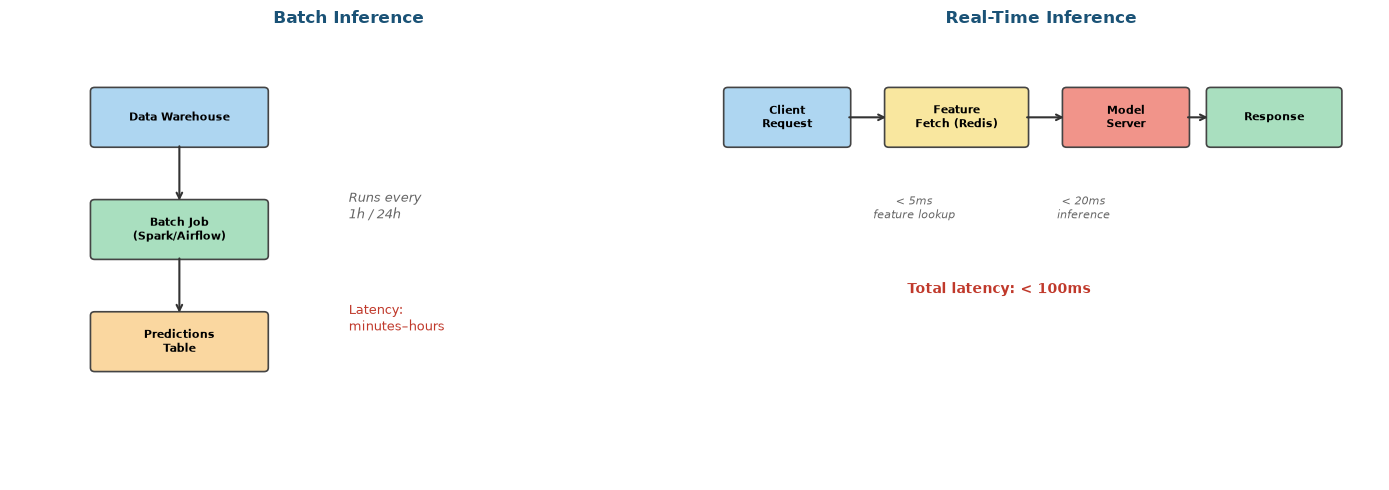

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

def draw_box(ax, x, y, w, h, text, color, fontsize=8):
    ax.add_patch(mpatches.FancyBboxPatch((x,y), w, h,
        boxstyle='round,pad=0.05', facecolor=color, edgecolor='#444', lw=1.2))
    ax.text(x+w/2, y+h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold')

def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
        arrowprops=dict(arrowstyle='->', color='#333', lw=1.5))

# --- BATCH ---
ax1.set_xlim(0,8); ax1.set_ylim(0,6); ax1.axis('off')
ax1.set_title('Batch Inference', fontsize=12, fontweight='bold', color='#1a5276')
items = [(1,4.5,2,0.7,'Data Warehouse','#AED6F1'),
         (1,3.0,2,0.7,'Batch Job\n(Spark/Airflow)','#A9DFBF'),
         (1,1.5,2,0.7,'Predictions\nTable','#FAD7A0')]
for args in items: draw_box(ax1,*args)
draw_arrow(ax1,2,4.5,2,3.7); draw_arrow(ax1,2,3.0,2,2.2)
ax1.text(4,3.5,'Runs every\n1h / 24h',fontsize=9,color='#666',style='italic')
ax1.text(4,2.0,'Latency:\nminutes–hours',fontsize=9,color='#c0392b')

# --- REAL-TIME ---
ax2.set_xlim(0,8); ax2.set_ylim(0,6); ax2.axis('off')
ax2.set_title('Real-Time Inference', fontsize=12, fontweight='bold', color='#1a5276')
items2 = [(0.3,4.5,1.4,0.7,'Client\nRequest','#AED6F1'),
          (2.2,4.5,1.6,0.7,'Feature\nFetch (Redis)','#F9E79F'),
          (4.3,4.5,1.4,0.7,'Model\nServer','#F1948A'),
          (6.0,4.5,1.5,0.7,'Response','#A9DFBF')]
for args in items2: draw_box(ax2,*args)
for x1,x2 in [(1.7,2.2),(3.8,4.3),(5.7,6.0)]: draw_arrow(ax2,x1,4.85,x2,4.85)
ax2.text(2.5,3.5,'< 5ms\nfeature lookup',fontsize=8,color='#666',style='italic',ha='center')
ax2.text(4.5,3.5,'< 20ms\ninference',fontsize=8,color='#666',style='italic',ha='center')
ax2.text(3.5,2.5,'Total latency: < 100ms',fontsize=10,color='#c0392b',ha='center',fontweight='bold')

plt.tight_layout(); plt.show()

## Scalability Concepts

| Concept | What It Is | ML Use Case |
|---------|-----------|-------------|
| **Horizontal scaling** | Add more machines | More model server replicas behind a load balancer |
| **Vertical scaling** | Bigger machine (more RAM/CPU/GPU) | Single large training job |
| **Load balancing** | Distribute requests across replicas | Round-robin across 5 model server pods |
| **Caching (Redis)** | Store frequently-used data in memory | Pre-computed user features for recommendation |
| **Message queue (Kafka)** | Async, durable event stream | Training data pipeline, prediction logging |
| **CDN** | Cache static content at edge | Model weights distributed globally |

**Rule of thumb:** Cache what's read often and changes rarely. Queue what needs to be processed reliably but not instantly.

In [3]:
# Architecture Decision Record — the artifact HLD produces
design_decisions = [
    {
        "component": "Feature Store",
        "choice": "Redis",
        "reason": "Sub-millisecond reads for real-time feature serving",
        "tradeoff": "Memory cost; limited to data that fits in RAM",
        "alternatives_rejected": ["PostgreSQL (too slow)", "DynamoDB (higher latency)"]
    },
    {
        "component": "Data Pipeline",
        "choice": "Apache Kafka + Flink",
        "reason": "High-throughput, fault-tolerant stream processing",
        "tradeoff": "Operational complexity; requires dedicated infra team",
        "alternatives_rejected": ["Airflow (batch only)", "Celery (not designed for streams)"]
    },
    {
        "component": "Model Serving",
        "choice": "FastAPI + Docker + Kubernetes",
        "reason": "Auto-scaling, rolling deploys, language-agnostic",
        "tradeoff": "K8s learning curve; cold-start latency",
        "alternatives_rejected": ["SageMaker (vendor lock-in)", "Flask (no async, slower)"]
    },
]

print("=" * 60)
print("ARCHITECTURE DECISION RECORDS")
print("=" * 60)
for i, d in enumerate(design_decisions, 1):
    print(f"\n[ADR-{i:02d}] {d['component']}")
    print(f"  Decision:    {d['choice']}")
    print(f"  Reason:      {d['reason']}")
    print(f"  Tradeoff:    {d['tradeoff']}")
    print(f"  Rejected:    {', '.join(d['alternatives_rejected'])}")

ARCHITECTURE DECISION RECORDS

[ADR-01] Feature Store
  Decision:    Redis
  Reason:      Sub-millisecond reads for real-time feature serving
  Tradeoff:    Memory cost; limited to data that fits in RAM
  Rejected:    PostgreSQL (too slow), DynamoDB (higher latency)

[ADR-02] Data Pipeline
  Decision:    Apache Kafka + Flink
  Reason:      High-throughput, fault-tolerant stream processing
  Tradeoff:    Operational complexity; requires dedicated infra team
  Rejected:    Airflow (batch only), Celery (not designed for streams)

[ADR-03] Model Serving
  Decision:    FastAPI + Docker + Kubernetes
  Reason:      Auto-scaling, rolling deploys, language-agnostic
  Tradeoff:    K8s learning curve; cold-start latency
  Rejected:    SageMaker (vendor lock-in), Flask (no async, slower)


## CAP Theorem for ML Systems

In any distributed system, you can guarantee **at most 2 of 3** properties:

- **C — Consistency**: Every read returns the most recent write (no stale data)
- **A — Availability**: Every request gets a response (even if some nodes are down)
- **P — Partition tolerance**: System works even if network splits occur (always required in real networks)

Since P is unavoidable, the real choice is **CP vs AP**:

| System | Choice | Why |
|--------|--------|-----|
| Model serving API | **AP** | Better to serve a slightly stale model than return 503 |
| Feature store | **CP** | Inconsistent features = wrong predictions = trust issues |
| Model registry | **CP** | You need to know exactly which model is deployed |
| Prediction logging | **AP** | Losing a few log lines beats dropping prediction requests |

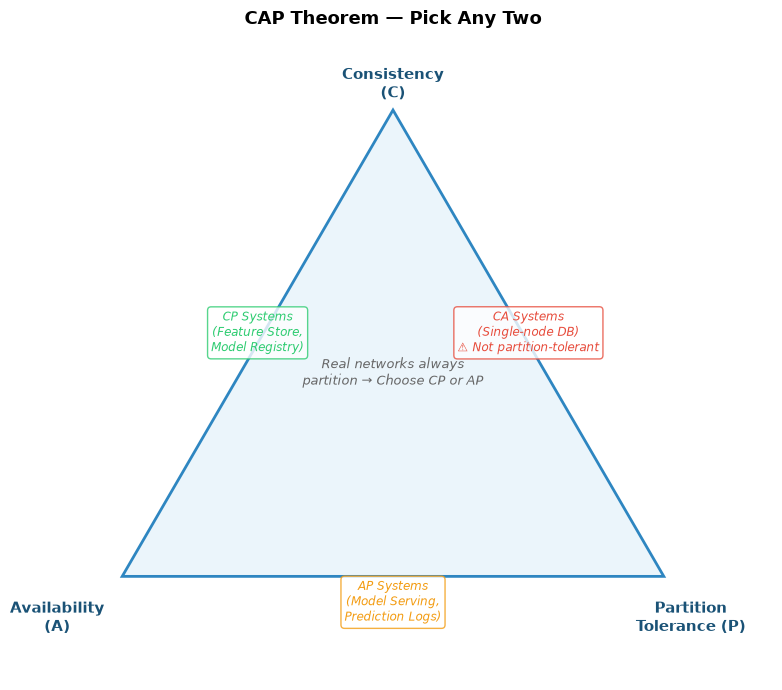

In [4]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 7))
ax.set_xlim(-0.2, 1.2); ax.set_ylim(-0.15, 1.1); ax.axis('off')
ax.set_title('CAP Theorem — Pick Any Two', fontsize=13, fontweight='bold')

vertices = np.array([[0.5, 0.95], [0.0, 0.05], [1.0, 0.05]])
triangle = plt.Polygon(vertices, fill=True, facecolor='#EBF5FB', edgecolor='#2E86C1', lw=2)
ax.add_patch(triangle)

labels = ['Consistency\n(C)', 'Availability\n(A)', 'Partition\nTolerance (P)']
offsets = [(0, 0.05), (-0.12, -0.08), (0.05, -0.08)]
for (vx, vy), label, (ox, oy) in zip(vertices, labels, offsets):
    ax.text(vx+ox, vy+oy, label, ha='center', va='center',
            fontsize=11, fontweight='bold', color='#1A5276')

# Edge labels
edge_labels = [
    (0.25, 0.52, 'CP Systems\n(Feature Store,\nModel Registry)', '#2ECC71'),
    (0.75, 0.52, 'CA Systems\n(Single-node DB)\n⚠ Not partition-tolerant', '#E74C3C'),
    (0.50, 0.00, 'AP Systems\n(Model Serving,\nPrediction Logs)', '#F39C12'),
]
for x, y, text, color in edge_labels:
    ax.text(x, y, text, ha='center', va='center', fontsize=8.5,
            color=color, style='italic',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor=color))

ax.text(0.5, 0.42, 'Real networks always\npartition → Choose CP or AP',
        ha='center', fontsize=9, color='#666', style='italic')
plt.tight_layout(); plt.show()

## Key Takeaways

1. **HLD is communication** — its output is a shared understanding, not running code
2. **Draw before you build** — 30 minutes of diagramming saves 3 days of refactoring
3. **Every choice is a tradeoff** — document *why* you chose something, not just *what*
4. **The model is 5% of the system** — feature pipelines, serving infra, and monitoring are the other 95%
5. **CAP is always in play** — explicitly choose CP or AP for each component based on failure mode consequences

### Additional Learning Resources
- *Designing Machine Learning Systems* — Chip Huyen (O'Reilly 2022)
- *Designing Data-Intensive Applications* — Martin Kleppmann (O'Reilly 2017)
- ML System Design Interview — Educative.io
- Google ML Engineering Practices: https://developers.google.com/machine-learning/guides
- Meta Engineering Blog: https://engineering.fb.com/category/ml-applications/